# Day 9: Introduction to Machine Learning

Machine Learning is a branch of Artificial Intelligence where a system learns patterns from data instead of following rules written by hand.

Topics in this notebook:

- Traditional programming versus machine learning
- The four types of machine learning
- Algorithms used for each type
- How a model is trained, evaluated and improved
- The full machine learning workflow

## What Machine Learning Is

Instead of hard coding every rule, we give the model examples and it figures out the mapping from inputs to outputs on its own.

Everyday examples:

- Spam email detection
- Netflix and YouTube recommendations
- House price prediction
- Fraud detection in payments

### Why Machine Learning Is Useful

- Handles very large datasets efficiently
- Keeps improving as more data arrives
- Finds patterns that a human might miss

One thing to remember: a model is only as good as the data it trains on. Bad data leads to bad predictions.

## Traditional Programming versus Machine Learning

In traditional programming we write the rules and the program produces an answer from the input. In machine learning we give the input together with the correct answer and the model works out the rules itself.

In [ ]:
# Traditional approach: a person writes the rules

def salary_band(years):
    if years < 2:
        return "Junior"
    elif years < 5:
        return "Mid-level"
    else:
        return "Senior"

for yrs in [1, 4, 8]:
    print(f"{yrs} years -> {salary_band(yrs)}")

1 years -> Junior
4 years -> Mid-level
8 years -> Senior


In [ ]:
# Machine learning approach: the model finds the pattern from examples

from sklearn.linear_model import LinearRegression

experience = [[1], [4], [8]]
salary = [32000, 68000, 115000]

model = LinearRegression()
model.fit(experience, salary)

print("Learned slope:", model.coef_[0].round(2))
print("Learned intercept:", model.intercept_.round(2))
print("Salary guess for 5 years:", model.predict([[5]]).round(2))

Learned slope: 11851.35
Learned intercept: 20310.81
Salary guess for 5 years: [79567.57]


## Types of Machine Learning

Machine learning is grouped by the way the model learns from data.

| Type | Data Used | Example |
|------|-----------|---------|
| Supervised | Labeled | Salary prediction |
| Unsupervised | Unlabeled | Customer segmentation |
| Semi-Supervised | A little labeled, mostly unlabeled | Medical image classification |
| Reinforcement | Rewards from an environment | Self-driving cars, game AI |

### Supervised Learning

The model trains on labeled data: every input already has a correct output, so it learns the relationship between features and the target.

In [ ]:
from sklearn.datasets import make_regression

X, y = make_regression(n_samples=25, n_features=2, noise=8, random_state=7)

print("Features:")
print(X[:5])
print("\nTargets:")
print(y[:5])
print("\nShape:", X.shape, y.shape)

Features:
[[-7.88923029e-01  2.06557291e-03]
 [-1.65107559e+00  5.35429356e-01]
 [ 8.40733242e-01 -1.79986401e-01]
 [-3.87139943e-01  2.02907222e+00]
 [-8.90385858e-04 -1.75472431e+00]]

Targets:
[ -42.28205219  -51.70049653   32.42272268  134.55277169 -124.67946636]

Shape: (25, 2) (25,)


### Unsupervised Learning

No labels are supplied. The model hunts for structure in the raw data, for example by grouping similar points into clusters.

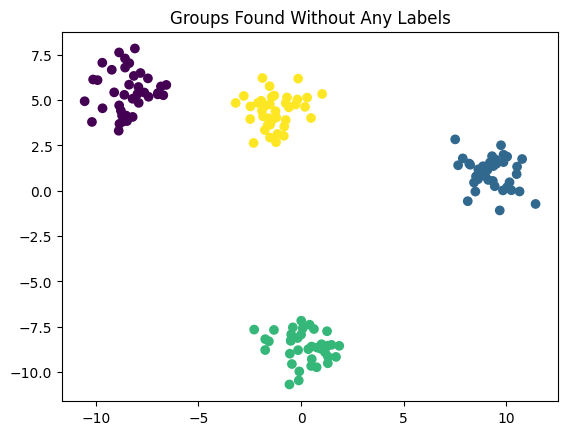

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

points, _ = make_blobs(n_samples=150, centers=4, random_state=7)

kmeans = KMeans(n_clusters=4, n_init="auto", random_state=7)
open_labels = kmeans.fit_predict(points)

plt.scatter(points[:, 0], points[:, 1], c=open_labels, cmap="viridis")
plt.title("Groups Found Without Any Labels")
plt.show()

### Semi-Supervised Learning

A small labeled portion guides the learning on a large unlabeled portion. This helps when collecting labels is expensive, such as in medical data.

In [1]:
from sklearn.semi_supervised import LabelPropagation
from sklearn.datasets import make_blobs
from sklearn.metrics import accuracy_score

blob_points, blob_targets = make_blobs(n_samples=60, centers=2, random_state=11)

view = blob_targets.copy()          # -1 marks an unlabeled row
view[::4] = -1
print("Rows kept labeled:", (view != -1).sum(), "of", len(view))

prop_model = LabelPropagation(kernel="rbf")
prop_model.fit(blob_points, view)

# check the propagated labels against the truth that was hidden
print("Agreement with hidden labels:",
      round(accuracy_score(blob_targets, prop_model.transduction_), 3))
print("First 10 propagated labels:", prop_model.transduction_[:10])

Rows kept labeled: 45 of 60
Agreement with hidden labels: 1.0
First 10 propagated labels: [0 0 0 1 1 0 0 1 1 1]


### Reinforcement Learning

An agent acts in an environment, gets rewards or penalties back, and slowly learns which actions pay off the most. The aim is to maximize the total reward over time.

In [ ]:
import random

# Two actions exist and the environment returns a reward after each pick
rewards = {"door_1": +40, "door_2": -12}
score = {"door_1": 0.0, "door_2": 0.0}

for episode in range(20):
    # try both once, then keep exploring sometimes
    if sum(score.values()) == 0 or random.random() < 0.2:
        action = random.choice(list(rewards))
    else:
        action = max(score, key=score.get)

    score[action] += rewards[action]

print("Total score per action:", score)
print("Model prefers:", max(score, key=score.get))

### Where Deep Learning and NLP Fit In

Deep Learning is not a fourth type of ML, it is a technique that uses neural networks with many layers and can be applied inside supervised, unsupervised or reinforcement problems.

Natural Language Processing is an application area rather than a type. Chatbots, translation and sentiment analysis all apply supervised and unsupervised methods to text.

## How the Types Are Differentiated

The types differ along three lines:

### Based on Data Availability

- Supervised: every input comes with a correct output
- Unsupervised: no outputs at all
- Semi-supervised: a few outputs, many bare inputs
- Reinforcement: no fixed dataset, only feedback from the environment

### Based on Learning Approach

- Supervised: learn an input to output mapping
- Unsupervised: discover clusters and hidden structure
- Semi-supervised: let labeled rows steer learning on unlabeled rows
- Reinforcement: learn by trial and error through rewards

### Based on Objective

- Supervised: prediction (classification or regression)
- Unsupervised: pattern discovery
- Semi-supervised: better performance with few labels
- Reinforcement: the best possible decision strategy

Short version of the idea:

- Supervised: input + output, learn, predict
- Unsupervised: input only, find patterns
- Reinforcement: action, reward, learn

Producing models is not separate from any of these; deep learning works across all of them, and NLP is a place where ordinary ML techniques are applied to language.

## Algorithms by Type

Each type of problem has its own family of algorithms.

### Supervised Algorithms

- Linear and Polynomial Regression for continuous targets
- Logistic Regression, Decision Tree, Random Forest, SVM, KNN and Naive Bayes for classification

They work by learning from labeled rows and minimizing the error between prediction and truth.

In [ ]:
from sklearn.metrics import mean_squared_error, accuracy_score

# quick supervised fit on the regression data above
from sklearn.linear_model import LinearRegression

X_small = X[:, [0]]                      # single feature version
model = LinearRegression().fit(X_small, y)
errors = mean_squared_error(y, model.predict(X_small))
print("Fit MSE:", round(errors, 3))

### Unsupervised Algorithms

- K-Means, Hierarchical Clustering and DBSCAN for clustering
- Principal Component Analysis (PCA) and t-SNE for dimensionality reduction

They get no labels: similar points are grouped and high dimensional data is squeezed into fewer dimensions while keeping its pattern.

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
import numpy as np

tree_clusters = AgglomerativeClustering(n_clusters=4).fit_predict(points)
print("Agglomerative cluster sizes:", np.bincount(tree_clusters))

reducer = PCA(n_components=2)
reduced = reducer.fit_transform(points)
print("Explained variance kept:", reducer.explained_variance_ratio_.round(3))

### Semi-Supervised Algorithms

- Self-training
- Label propagation and label spreading
- Semi-supervised SVM

A base model is trained on the small labeled set, labels are predicted for the unlabeled rows, then the model is retrained on the combined data. The LabelPropagation demo earlier showed this directly.

### Reinforcement Algorithms

- Q-Learning
- SARSA
- Deep Q Networks
- Policy gradient methods

Deep learning plugs into every type: CNNs for image classification, autoencoders for unsupervised feature learning, Deep Q Networks for game playing. NLP tools such as TF-IDF, Word2Vec and Transformers are built on the same ML ideas.

| Type | Typical Algorithms | Main Use |
|------|--------------------|----------|
| Supervised | Regression, SVM, Trees | Prediction |
| Unsupervised | K-Means, PCA | Pattern finding |
| Semi-Supervised | Label Propagation | Few labels |
| Reinforcement | Q-Learning | Decision making |

## How a Model Is Trained

A complete training cycle looks like this:

1. Collect data
2. Preprocess it
3. Split into train and test
4. Train the model
5. Predict
6. Evaluate
7. Improve

### Sample Dataset for the Full Cycle

A small employee table plays the role of collected raw data.

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(3)
sample_data = pd.DataFrame({
    "YearsExperience": np.round(np.random.uniform(1, 10, 40), 1),
    "Performance": np.random.choice([1, 2, 3], 40),
})
sample_data["Salary"] = 32000 + 9000 * sample_data["YearsExperience"] \
                        + 3000 * sample_data["Performance"]
sample_data.loc[[3, 17], "Salary"] = np.nan   # simulate missing records
sample_data.head()

### Preprocessing

Missing rows are dropped before anything else happens.

In [ ]:
sample_data = sample_data.dropna()
print("Rows remaining:", len(sample_data))

### Train-Test Split

The data is divided so the model learns from one part and is judged on another part it has never seen.

In [ ]:
from sklearn.model_selection import train_test_split

feat = sample_data[["YearsExperience", "Performance"]]
targ = sample_data["Salary"]

feat_train, feat_test, targ_train, targ_test = train_test_split(
    feat, targ, test_size=0.2, random_state=3
)
print(len(feat_train), "training rows,", len(feat_test), "test rows")

### Training and Prediction

During training the model compares its guess with the real salary and shifts its weights toward smaller error.

In [ ]:
from sklearn.linear_model import SGDRegressor

regressor = SGDRegressor(max_iter=1, tol=None, eta0=0.01, random_state=3)

### Epochs and Loss

One epoch is a single full pass over the training data. Each pass the loss, here the MSE, should drop.

In [ ]:
import matplotlib.pyplot as plt

loss_history = []
for epoch in range(40):
    regressor.partial_fit(feat_train, targ_train)      # one pass
    current_mse = mean_squared_error(
        targ_train, regressor.predict(feat_train)
    )
    loss_history.append(current_mse)

print("Loss after epoch 1 :", round(loss_history[0], 2))
print("Loss after epoch 40:", round(loss_history[-1], 2))

plt.plot(range(1, 41), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Loss Shrinks as Epochs Pass")
plt.show()

### Evaluation

Prediction quality is measured on the untouched test rows.

In [ ]:
from sklearn.metrics import r2_score

guesses = regressor.predict(feat_test)

print("Test MSE :", round(mean_squared_error(targ_test, guesses), 2))
print("Test RMSE:", round(np.sqrt(mean_squared_error(targ_test, guesses)), 2))
print("R2 score :", round(r2_score(targ_test, guesses), 3))

### Evaluation for Classification Problems

When the output is a category instead of a number, accuracy, precision, recall and the F1 score take over.

In [ ]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

cls_X, cls_y = make_classification(
    n_samples=300, n_features=4, random_state=3
)
cls_X_train, cls_X_test, cls_y_train, cls_y_test = train_test_split(
    cls_X, cls_y, test_size=0.25, random_state=3
)

classifier = LogisticRegression().fit(cls_X_train, cls_y_train)
cls_pred = classifier.predict(cls_X_test)

print("Accuracy:", round(accuracy_score(cls_y_test, cls_pred), 4))
print(confusion_matrix(cls_y_test, cls_pred))
print(classification_report(cls_y_test, cls_pred))

### Overfitting and Underfitting

High training performance with weak test performance means the model memorized the training rows. Low scores on both mean it learned too little.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

for depth in [1, 2, 12]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=3)
    tree.fit(feat_train, targ_train)
    print(f"depth={depth:2}  train R2={tree.score(feat_train, targ_train):.3f}"
          f"  test R2={tree.score(feat_test, targ_test):.3f}")

## End-to-End ML Pipeline

The same cycle in production form:

Data collection, preprocessing, EDA, feature engineering, model development, training, evaluation, then saving the model for later use.

### Data Collection

Raw data can come from CSV files, SQL databases, APIs, web scraping or sensor logs. Anything that captures behavior, such as user clicks or purchases, counts.

### Preprocessing and EDA

Cleaning covers missing values, duplicates, categorical encoding and scaling. EDA with histograms, boxplots and correlation matrices then exposes patterns and outliers before any training.

### Feature Engineering and Model Development

New meaningful columns, encoding and selection improve what the model sees. Then an algorithm is picked to match the problem: regression for numbers, decision trees or SVM for classification, K-Means for grouping.

### Saving the Model

A trained model can be stored to disk and reloaded without retraining.

In [ ]:
import pickle

with open("salary_model.pkl", "wb") as fh:
    pickle.dump(regressor, fh)

with open("salary_model.pkl", "rb") as fh:
    loaded = pickle.load(fh)

print("Reloaded model test R2:",
      round(loaded.score(feat_test, targ_test), 3))

## From Saved Model to Production

The steps after saving are about making the model useful and keeping it useful:

### Deployment as an API

The model is exposed behind a web service so that other systems can send inputs and receive predictions.

### Backend and Frontend

The backend passes user input to the model and returns the result; the frontend is the web page, dashboard or app the user touches.

### Hosting and Monitoring

The service runs on a cloud platform for availability, and its accuracy, input patterns and speed are watched continuously.

### Drift and Retraining

- Data drift: incoming data slowly changes shape
- Model drift: accuracy falls because of that change

When this happens, fresh data is collected, the model is retrained, evaluated again and redeployed.

The real-world loop: user sends input, the frontend forwards it, the backend calls the model, the prediction returns. Systems are not built once, they cycle through build, deploy, monitor and improve.

## Practice

### Q1. Generate labeled regression data and print its shapes

In [ ]:
demo_X, demo_y = make_regression(n_samples=50, n_features=3, noise=10, random_state=11)
print(demo_X.shape, demo_y.shape)
print("Sample target values:", demo_y[:5].round(2))

### Q2. Split it into 80 training / 20 testing

In [ ]:
demo_X_tr, demo_X_te, demo_y_tr, demo_y_te = train_test_split(
    demo_X, demo_y, test_size=0.2, random_state=11
)
print(len(demo_X_tr), "train /", len(demo_X_te), "test")

### Q3. Fit LinearRegression and print the R2 score on test data

In [ ]:
demo_lin = LinearRegression().fit(demo_X_tr, demo_y_tr)
print("Test R2:", round(r2_score(demo_y_te, demo_lin.predict(demo_X_te)), 3))

### Q4. Cluster random blobs with KMeans and plot the result

In [ ]:
blobs, _ = make_blobs(n_samples=200, centers=3, random_state=11)
labels_found = KMeans(n_clusters=3, n_init="auto", random_state=11).fit_predict(blobs)

plt.scatter(blobs[:, 0], blobs[:, 1], c=labels_found, cmap="plasma")
plt.title("Three Discovered Groups")
plt.show()

### Q5. Compute MSE and RMSE by hand and compare with sklearn

In [ ]:
manual_mse = ((demo_y_te - demo_lin.predict(demo_X_te)) ** 2).mean()
sk_mse = mean_squared_error(demo_y_te, demo_lin.predict(demo_X_te))

print("Manual MSE :", round(manual_mse, 3))
print("Sklearn MSE:", round(sk_mse, 3))
print("RMSE       :", round(np.sqrt(manual_mse), 3))

### Q6. Print a classification report for a synthetic classification problem

In [ ]:
cx, cy = make_classification(n_samples=150, weights=[0.7, 0.3], random_state=5)
cx_tr, cx_te, cy_tr, cy_te = train_test_split(cx, cy, test_size=0.3, random_state=5)

clf = LogisticRegression().fit(cx_tr, cy_tr)
print(classification_report(cy_te, clf.predict(cx_te)))

### Q7. Save a trained model with pickle and verify it loads back

In [ ]:
with open("practice_model.pkl", "wb") as out_file:
    pickle.dump(demo_lin, out_file)

with open("practice_model.pkl", "rb") as in_file:
    restored = pickle.load(in_file)

print("Same predictions?",
      np.array_equal(restored.predict(demo_X_te), demo_lin.predict(demo_X_te)))

### Q8. Show overfitting with a deep decision tree

In [ ]:
deep_tree = DecisionTreeRegressor(random_state=11).fit(demo_X_tr, demo_y_tr)
print("Train R2:", round(deep_tree.score(demo_X_tr, demo_y_tr), 3))
print("Test  R2:", round(deep_tree.score(demo_X_te, demo_y_te), 3))